# Importing libraries

In [34]:
import cv2 as cv
import numpy as np
import seaborn as sn
import tensorflow as tf
from matplotlib import pyplot
from keras.datasets import cifar10
from keras.utils import to_categorical
from keras.models import Sequential
from keras.layers import Conv2D
from keras.layers import MaxPooling2D
from keras.layers import Dense
from keras.layers import Flatten
from keras.layers import Dropout
from keras.layers import BatchNormalization
from keras.optimizers import SGD
from keras.preprocessing.image import ImageDataGenerator
from sklearn.metrics import classification_report

# Load the dataset

In [47]:
(trainX, trainY), (testX, testY) = cifar10.load_data()
trainY = to_categorical(trainY)
testY = to_categorical(testY)

# Preparing pixels

In [48]:
trainX = trainX.astype('float32')
testX = testX.astype('float32')
trainX = trainX / 255.0
testX = testX / 255.0

# Building the model

In [4]:
model = Sequential()
model.add(Conv2D(32, (3, 3), activation='relu', kernel_initializer='he_uniform', padding='same', input_shape=(32, 32, 3)))
model.add(BatchNormalization())
model.add(Conv2D(32, (3, 3), activation='relu', kernel_initializer='he_uniform', padding='same'))
model.add(BatchNormalization())
model.add(MaxPooling2D((2, 2)))
model.add(Dropout(0.2))
model.add(Conv2D(64, (3, 3), activation='relu', kernel_initializer='he_uniform', padding='same'))
model.add(BatchNormalization())
model.add(Conv2D(64, (3, 3), activation='relu', kernel_initializer='he_uniform', padding='same'))
model.add(BatchNormalization())
model.add(MaxPooling2D((2, 2)))
model.add(Dropout(0.3))
model.add(Conv2D(128, (3, 3), activation='relu', kernel_initializer='he_uniform', padding='same'))
model.add(BatchNormalization())
model.add(Conv2D(128, (3, 3), activation='relu', kernel_initializer='he_uniform', padding='same'))
model.add(BatchNormalization())
model.add(MaxPooling2D((2, 2)))
model.add(Dropout(0.4))
model.add(Flatten())
model.add(Dense(128, activation='relu', kernel_initializer='he_uniform'))
model.add(BatchNormalization())
model.add(Dropout(0.5))
model.add(Dense(10, activation='softmax'))
opt = SGD(learning_rate=0.001, momentum=0.9)
model.compile(optimizer=opt, loss='categorical_crossentropy', metrics=['accuracy'])

# Data augmentation

In [5]:
datagen = ImageDataGenerator(width_shift_range=0.1, height_shift_range=0.1, horizontal_flip=True)
it_train = datagen.flow(trainX, trainY, batch_size=64)

# Train the model

In [6]:
steps = int(trainX.shape[0] / 64)
history = model.fit(it_train, steps_per_epoch=steps, epochs=400, validation_data=(testX, testY), verbose=0)

# Evaluating the model

In [7]:
_, acc = model.evaluate(testX, testY, verbose=0)
print('> %.3f' % (acc * 100.0))

> 88.570


# Classification report

In [15]:
predictions = model.predict(testX, verbose=0)
predY = [np.argmax(i) for i in predictions]
predY = to_categorical(predY)
print(classification_report(testY, predY))

              precision    recall  f1-score   support

           0       0.90      0.90      0.90      1000
           1       0.93      0.97      0.95      1000
           2       0.89      0.82      0.85      1000
           3       0.80      0.77      0.79      1000
           4       0.85      0.89      0.87      1000
           5       0.86      0.79      0.82      1000
           6       0.81      0.97      0.88      1000
           7       0.95      0.88      0.91      1000
           8       0.95      0.94      0.94      1000
           9       0.94      0.94      0.94      1000

   micro avg       0.89      0.89      0.89     10000
   macro avg       0.89      0.89      0.89     10000
weighted avg       0.89      0.89      0.89     10000
 samples avg       0.89      0.89      0.89     10000



# Plot history

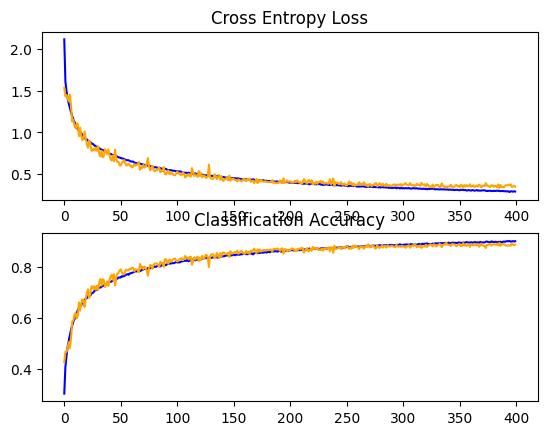

In [9]:
pyplot.subplot(2, 1, 1)
pyplot.title('Cross Entropy Loss')
pyplot.plot(history.history['loss'], color='blue', label='train')
pyplot.plot(history.history['val_loss'], color='orange', label='test')
pyplot.subplot(2, 1, 2)
pyplot.title('Classification Accuracy')
pyplot.plot(history.history['accuracy'], color='blue', label='train')
pyplot.plot(history.history['val_accuracy'], color='orange', label='test')
pyplot.show()

# Confusion matrix

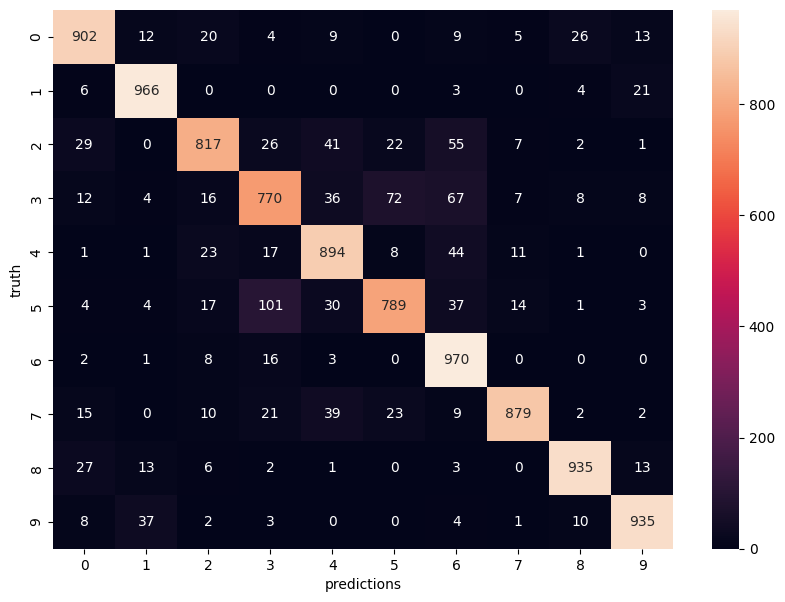

In [49]:
predictions = model.predict(testX, verbose=0)
predY = [np.argmax(i) for i in predictions]
testY = [np.argmax(i) for i in testY]
cm = tf.math.confusion_matrix(labels = testY, predictions = predY)
pyplot.figure(figsize = (10, 7))
sn.heatmap(cm, annot = True, fmt = 'd')
pyplot.xlabel('predictions')
pyplot.ylabel('truth')
pyplot.show()

# Make a prediction

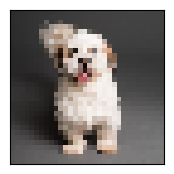

In [51]:
img = cv.imread('../images/dog.jpg')
img = cv.cvtColor(img, cv.COLOR_BGR2RGB)
img = cv.resize(img, (32, 32))
pyplot.figure(figsize = (15, 2))
pyplot.xticks([])
pyplot.yticks([])
pyplot.imshow(img)
pyplot.show()

In [52]:
classes = ['plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
prediction = model.predict(np.array([img]) / 255, verbose=0)
print("prediction:",classes[np.argmax(prediction)])

prediction: dog


# Save the model

In [53]:
model.save('../models/finalmodel.keras')